# R-MOVE · Impacto de las incidencias de Rodalies en los viajes hacia Barcelona

**Pregunta:** ¿las incidencias graves de Rodalies reducen los viajes hacia Barcelona? ¿Dónde?

**Datos:** movilidad diaria de Telefónica (M2, municipio de origen → Barcelona, 2023–2025),
estaciones de Rodalies, incidencias graves y meteorología (Open-Meteo).

**Dos métodos:**
1. **Clustering + mediana:** se clasifica cada día en un tipo (A/B/C) según la movilidad de los
   municipios sin Rodalies, y se compara el día de incidencia con los días normales de su mismo tipo.
2. **Regresión (diferencias en diferencias):** se comparan, el mismo día, los municipios
   dependientes de Rodalies con los municipios sin Rodalies.

In [2]:
%pip install holidays pyarrow openpyxl pyfixest -q
import re, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, requests, holidays
import pyarrow.parquet as pq
import pyfixest as pf
from dateutil.easter import easter
from sklearn.cluster import KMeans
pd.set_option("display.max_rows", 100)

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Configuración

In [4]:
ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
RAW, PROC = ROOT / "data" / "raw", ROOT / "data" / "processed"
OUT = PROC / "rmove"; OUT.mkdir(parents=True, exist_ok=True)

F_M2      = PROC / "telefonica" / "M2.parquet"
F_EST_MUN = OUT / "estaciones_rodalies_municipio.csv"
F_INC     = next((RAW / "rodalies").glob("Incidencias graves Rodalies*.xlsx"), None)

INICIO, FIN = "2023-01-01", "2025-08-31"
BCN_CODE    = "08019"
SEGMENTOS   = ["Regional", "Residente"]
LINEAS      = ["R1", "R2N", "R2S", "R3", "R4", "R7"]
MUN_CON_ALTERNATIVA = ["Sabadell", "Terrassa", "Rubí", "Sant Cugat del Vallès", "Martorell", "Manresa",
                       "Hospitalet de Llobregat, L'", "Badalona", "Cornellà de Llobregat", "Prat de Llobregat, El",
                       "Sant Adrià de Besòs", "Sant Joan Despí", "Sant Feliu de Llobregat"]
DIST_MIN_KM = 20                      # municipio dependiente: a ≥ 20 km de Barcelona y sin metro/FGC
MIN_VIAJES  = 200                     # municipios con al menos 200 viajes/día a Barcelona
VERANO      = ("06-21", "09-10")
LLUVIA_DIA, LLUVIA_MANANA, RACHA = 2.0, 0.5, 60
K_VOL       = 3                       # tipos de día del clustering: A (bajo), B (medio), C (alto)

DIAS_CAOS = {"2024-05-13": "Avería: robo de cobre en Montcada (día 1)",
             "2025-03-17": "Huelga (caos generalizado)",
             "2025-03-19": "Huelga (paros parciales)",
             "2025-03-26": "Huelga 24 h",
             "2025-04-01": "Huelga 24 h"}
for f in [F_M2, F_EST_MUN, F_INC]:
    print(("✅" if f is not None and f.exists() else "❌ NO EXISTE"), f)

✅ c:\Users\marti\R-MOVE\data\processed\telefonica\M2.parquet
✅ c:\Users\marti\R-MOVE\data\processed\rmove\estaciones_rodalies_municipio.csv
✅ c:\Users\marti\R-MOVE\data\raw\rodalies\Incidencias graves Rodalies 2023–2025.xlsx


## 2. Datos

- **Movilidad (M2):** viajes diarios desde cada municipio de la provincia hacia Barcelona.
  Se usan los segmentos *Regional* y *Residente* (movilidad cotidiana); se excluyen *Nacional*
  e *Internacional* (turismo).
- **Estaciones:** cada estación de Rodalies asignada a su municipio (código INE) a partir del GTFS de Renfe.
- **Incidencias:** días afectados por las 10 incidencias más graves de 2023–2025 (se usan para
  excluirlos de los días de referencia).

M2 - Movilidad Telefónica

In [11]:
cols = ["day", "origen", "municipio_origen", "municipio_origen_name", "municipio_destino", "viajes"]
if F_M2.suffix == ".parquet":
    mov = pq.read_table(F_M2, columns=cols, filters=[("municipio_destino", "==", BCN_CODE)]).to_pandas()
    if mov.empty:
        mov = pq.read_table(F_M2, columns=cols, filters=[("municipio_destino", "==", int(BCN_CODE))]).to_pandas()
else:
    mov = pd.read_csv(F_M2, usecols=cols, dtype={"municipio_origen": str, "municipio_destino": str})
mov["municipio_origen"] = mov.municipio_origen.astype(str).str.zfill(5)
mov["municipio_destino"] = mov.municipio_destino.astype(str).str.zfill(5)
mov = mov[(mov.municipio_destino == BCN_CODE) & (mov.municipio_origen != BCN_CODE) & mov.origen.isin(SEGMENTOS)]
mov["fecha"] = pd.to_datetime(mov.day)
mov = mov[(mov.fecha >= INICIO) & (mov.fecha <= FIN)]
nombres_mun = mov.drop_duplicates("municipio_origen").set_index("municipio_origen").municipio_origen_name
print(mov.shape, "|", mov.fecha.min().date(), "→", mov.fecha.max().date(), "| municipios de origen:", mov.municipio_origen.nunique())
mov["viajes"] = mov.viajes.astype(float)

(516238, 7) | 2023-01-01 → 2025-08-31 | municipios de origen: 308


Municipios y Líneas Rodalies

In [12]:
est = pd.read_csv(F_EST_MUN, dtype={"stop_id": str, "municipio_code": str}).dropna(subset=["municipio_code"])
lineas = (est.assign(linea=est.lineas.str.split(",")).explode("linea")
             .query("linea in @LINEAS and municipio_code != @BCN_CODE")
             .drop_duplicates(["linea", "municipio_code"])[["linea", "municipio_code", "municipio"]])
display(lineas.groupby("linea").municipio.nunique().rename("municipios"))

linea
R1     19
R2N    13
R2S     8
R3     16
R4     25
R7      2
Name: municipios, dtype: int64

In [13]:
dias_inc = pd.read_excel(F_INC, sheet_name="Días afectados")
def lineas_de_texto(txt):
    t = str(txt)
    if re.search(r"general|total|toda la red|todas|casi toda", t, re.I):
        return list(LINEAS)
    out = set()
    for m in re.finditer(r"R(\d+)\s*(Nord|Sud|N\b|S\b)?", t, re.I):
        cod = f"R{m.group(1)}{(m.group(2) or '').upper()[:1]}"
        out |= {"R2N", "R2S"} if cod == "R2" else {cod}
    if re.search(r"regionales sur", t, re.I): out.add("R2S")
    return sorted(out & set(LINEAS))
dias_inc["lineas"] = dias_inc["Afectación ese día"].map(lineas_de_texto)
incid = (dias_inc.explode("lineas").dropna(subset=["lineas"])
         .rename(columns={"Fecha": "fecha", "lineas": "linea", "# ranking": "id_incidencia"})[["fecha", "linea", "id_incidencia"]])
incid["fecha"] = pd.to_datetime(incid.fecha)
print("Días con incidencia grave:", incid.fecha.nunique())

Días con incidencia grave: 64


**Incidencias graves.** Se parte de un ranking de las 10 incidencias más graves de Rodalies entre
2023 y agosto de 2025, elaborado a partir de noticias de prensa (no se dispone de un registro oficial).
La gravedad combina, por orden de peso, el alcance (toda la red, varias líneas troncales o un tramo),
la duración, el tipo de interrupción (corte total, vía única o frecuencias reducidas) y el número de
viajeros afectados. Los días de caos analizados son el primer día del robo de cobre de Montcada
(13/05/2024) y tres jornadas de huelga de 2025 con alteración real del servicio.

## 3. Días de referencia («días limpios»)

Para saber qué es un día «normal», se descartan los días con un comportamiento distinto:
fines de semana, festivos (Cataluña y Barcelona), puentes, Navidad, Semana Santa, verano
(21/06–10/09), eventos (MWC, Sant Jordi, apagón), huelgas, días de mal tiempo (lluvia ≥ 2 mm/día,
≥ 0,5 mm entre las 6 y las 10 h o rachas ≥ 60 km/h, ponderadas por los viajes de cada municipio)
y días con incidencias graves.

**Control de calidad:** en el análisis exploratorio se detectaron cinco días con errores en los
datos de origen (05/06/2023, 12/02/2024, 07/03/2024, 19/05/2025 y 21/05/2025): caídas del 25–70 %
en todos los municipios, incluidos L'Hospitalet (con metro) y los visitantes internacionales. Se
excluyen como «anomalía de datos».

**Calendario.** Se marca cada día del periodo según si es fin de semana, festivo (Cataluña y
Barcelona), puente, Navidad, Semana Santa o verano, y se añaden los días especiales: MWC,
Sant Jordi, apagón, huelgas y los cinco días con anomalías en los datos.

In [14]:
cal = pd.DataFrame(index=pd.date_range(INICIO, FIN, freq="D"))
cal["dow"] = cal.index.day_of_week
cal["finde"] = cal.dow >= 5
md_ = cal.index.strftime("%m-%d")
anys = range(int(INICIO[:4]), int(FIN[:4]) + 1)
fest_ct = holidays.Spain(subdiv="CT", years=anys)
locales_bcn = pd.to_datetime(["2023-05-29", "2023-09-25", "2024-05-20", "2024-09-24", "2025-06-09"])
cal["festivo"] = cal.index.isin(pd.to_datetime(list(fest_ct.keys()))) | cal.index.isin(locales_bcn)
no_lab = cal.finde | cal.festivo
cal["puente"] = ~no_lab & no_lab.shift(1, fill_value=False) & no_lab.shift(-1, fill_value=False)
cal["navidad"] = (md_ >= "12-22") | (md_ <= "01-07")
ss = []
for y in anys:
    e = pd.Timestamp(easter(y)); ss += list(pd.date_range(e - pd.Timedelta(days=8), e + pd.Timedelta(days=1)))
cal["semana_santa"] = cal.index.isin(ss)
cal["verano"] = (md_ >= VERANO[0]) & (md_ <= VERANO[1])

eventos = {
    "MWC": list(pd.date_range("2023-02-27", "2023-03-02")) + list(pd.date_range("2024-02-26", "2024-02-29"))
         + list(pd.date_range("2025-03-03", "2025-03-06")),
    "Sant Jordi": list(pd.to_datetime(["2024-04-23", "2025-04-23"])),
    "Apagón": [pd.Timestamp("2025-04-28")],
    "Anomalía de datos": list(pd.to_datetime(["2023-06-05", "2024-02-12", "2024-03-07", "2025-05-19", "2025-05-21"])),
    "Huelgas": list(pd.to_datetime(["2023-11-23", "2023-11-24", "2024-02-09", "2024-02-16",
                                    "2025-03-17", "2025-03-19", "2025-03-26", "2025-04-01"])),
}
cal["evento"], cal["evento_nombre"] = False, ""
for nombre, dias in eventos.items():
    m = cal.index.isin(dias); cal.loc[m, "evento"] = True; cal.loc[m, "evento_nombre"] = nombre

**Meteorología.** Se descarga la lluvia y el viento diarios de Open-Meteo para cada municipio
con estación (se guarda en caché). Se calcula la lluvia media ponderada por los viajes de cada
municipio y se marca como «mal tiempo» el día con lluvia ≥ 2 mm, ≥ 0,5 mm entre las 6 y las 10 h,
lluvia en Barcelona ≥ 2 mm o rachas ≥ 60 km/h.

In [15]:
def meteo(lat, lon):
    p = dict(latitude=lat, longitude=lon, start_date=INICIO, end_date=FIN,
             daily="precipitation_sum,wind_gusts_10m_max", hourly="precipitation", timezone="Europe/Madrid")
    j = requests.get("https://archive-api.open-meteo.com/v1/archive", params=p, timeout=60).json()
    if "daily" not in j: raise RuntimeError(j)
    d = pd.DataFrame(j["daily"]); d["time"] = pd.to_datetime(d.time); d = d.set_index("time")
    h = pd.DataFrame(j["hourly"]); h["time"] = pd.to_datetime(h.time); h = h.set_index("time")
    d["lluvia_manana"] = h.between_time("06:00", "10:00").precipitation.resample("D").sum()
    return d

coords = est.groupby("municipio_code")[["stop_lat", "stop_lon"]].mean()
coords = coords[coords.index.isin(set(lineas.municipio_code) | {BCN_CODE})]
alt_codes = set(lineas.loc[lineas.municipio.isin(MUN_CON_ALTERNATIVA), "municipio_code"])
pesos = (mov[mov.municipio_origen.isin(set(lineas.municipio_code) - alt_codes)]
           .groupby("municipio_origen").viajes.sum().astype(float) / mov.fecha.nunique())

cache = OUT / f"meteo_{INICIO}_{FIN}.parquet"
if cache.exists():
    meteo_long = pd.read_parquet(cache)
else:
    trozos = []
    for code_, (lat, lon) in coords.iterrows():
        d = None
        for intento in range(5):
            try: d = meteo(lat, lon); break
            except Exception as e: print(code_, "reintento", intento, e); time.sleep(65)
        if d is not None:
            trozos.append(d[["precipitation_sum", "lluvia_manana", "wind_gusts_10m_max"]].assign(municipio_code=code_))
        time.sleep(6)
    meteo_long = pd.concat(trozos).rename_axis("fecha").reset_index(); meteo_long.to_parquet(cache)

def ponderada(col):
    w = meteo_long.pivot(index="fecha", columns="municipio_code", values=col).astype(float)
    w = w[[c for c in w.columns if c in pesos.index]]
    p = pesos.reindex(w.columns).astype(float).to_numpy()
    num = np.nansum(w.to_numpy() * p, axis=1)
    den = (w.notna().to_numpy() * p).sum(axis=1)
    return pd.Series(np.where(den > 0, num / den, np.nan), index=w.index)

cal["lluvia_pond"] = ponderada("precipitation_sum")
cal["lluvia_manana_pond"] = ponderada("lluvia_manana")
cal["racha_pond"] = ponderada("wind_gusts_10m_max")
cal["lluvia_bcn"] = meteo_long[meteo_long.municipio_code == BCN_CODE].set_index("fecha").precipitation_sum
cal["mal_tiempo"] = ((cal.lluvia_pond >= LLUVIA_DIA) | (cal.lluvia_manana_pond >= LLUVIA_MANANA)
                     | (cal.lluvia_bcn >= LLUVIA_DIA) | (cal.racha_pond >= RACHA)).fillna(False)

**Días limpios y días de caos.** Un día es «limpio» (referencia de un día normal) si no cumple
ninguno de los motivos de exclusión y no tiene incidencias graves. La tabla muestra cuántos días
excluye cada motivo. Por último, se seleccionan los días de caos que se pueden analizar
(laborables, fuera de verano y sin lluvia).

In [16]:
motivos = ["finde", "festivo", "puente", "navidad", "semana_santa", "verano", "evento", "mal_tiempo"]
cal["base_ok"] = ~cal[motivos].any(axis=1)
cal["limpio"] = cal.base_ok & ~cal.index.isin(incid.fecha)
display(pd.DataFrame({"días excluidos": cal[motivos].sum(),
                      "excluidos solo por este motivo": cal[motivos][cal[motivos].sum(axis=1) == 1].sum()}))
print("Días limpios por año:", cal[cal.limpio].groupby(cal[cal.limpio].index.year).size().to_dict())

caos_real = [pd.Timestamp(d) for d in DIAS_CAOS
             if INICIO <= d <= FIN and not (cal.at[pd.Timestamp(d), "finde"] or cal.at[pd.Timestamp(d), "festivo"]
                                             or cal.at[pd.Timestamp(d), "verano"] or cal.at[pd.Timestamp(d), "mal_tiempo"])]
display(pd.DataFrame({"descripción": [DIAS_CAOS[d.strftime("%Y-%m-%d")] for d in caos_real],
                      "lluvia_mm": [round(cal.at[d, "lluvia_pond"], 1) for d in caos_real]}, index=[d.date() for d in caos_real]))
print("Días de caos descartados:", [d for d in DIAS_CAOS if pd.Timestamp(d) not in caos_real])

,días excluidos,excluidos solo por este motivo
finde,279,135
festivo,38,12
puente,8,2
navidad,41,18
semana_santa,30,6
verano,236,127
evento,28,22
mal_tiempo,233,112


Días limpios por año: {2023: 124, 2024: 103, 2025: 70}


,descripción,lluvia_mm
2024-05-13,Avería: robo de cobre en Montcada (día 1),0.0
2025-03-17,Huelga (caos generalizado),0.5
2025-03-26,Huelga 24 h,0.4
2025-04-01,Huelga 24 h,0.1


Días de caos descartados: ['2025-03-19']


**Resultado.** Quedan unos 300 días laborables limpios (≈ 124 en 2023, ≈ 103 en 2024 y ≈ 70 en
2025, año parcial). Se analizan **4 días de caos**: el 13/05/2024 (robo de cobre en Montcada) y
las huelgas del 17/03, 26/03 y 01/04/2025. El 19/03/2025 se descarta por lluvia intensa (26 mm).
Las huelgas de noviembre de 2023 no se incluyen porque se desconvocaron y el servicio fue casi normal.

## 4. Clasificación de municipios

Cada municipio con al menos 200 viajes diarios a Barcelona se clasifica en:

| Grupo | Definición | Papel |
|---|---|---|
| **Dependiente** | Estación de Rodalies, sin metro ni FGC y a ≥ 20 km de Barcelona | Tratado: depende del tren |
| **Cercano sin metro/FGC** | Estación de Rodalies, sin metro ni FGC, a < 20 km | Tiene bus metropolitano |
| **Con metro/FGC** | Estación de Rodalies y metro o FGC | Tiene alternativa ferroviaria |
| **Sin Rodalies** | Sin estación de Rodalies | **Control**: ninguna incidencia de Rodalies le afecta |

In [17]:
PLAZA_CAT = (41.3874, 2.1686)
def km(lat, lon):
    la1, lo1, la2, lo2 = map(np.radians, [lat, lon, *PLAZA_CAT])
    return 6371 * 2 * np.arcsin(np.sqrt(np.sin((la2 - la1) / 2) ** 2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2))

lineas_mun = lineas.groupby("municipio_code").agg(lineas=("linea", lambda s: frozenset(s)), municipio=("municipio", "first"))
lineas_mun["linea_dep"] = lineas_mun.lineas.map(lambda s: "+".join(sorted(s)))
lineas_mun["con_alternativa"] = lineas_mun.municipio.isin(MUN_CON_ALTERNATIVA)
lineas_mun["dist_km"] = est.groupby("municipio_code")[["stop_lat", "stop_lon"]].mean().apply(
    lambda r: km(r.stop_lat, r.stop_lon), axis=1).reindex(lineas_mun.index).round(1)
lineas_mun["dependiente"] = ~lineas_mun.con_alternativa & (lineas_mun.dist_km >= DIST_MIN_KM)

# Panel municipio × día: días limpios + días de caos
todos = mov.groupby(["municipio_origen", "fecha"]).viajes.sum().rename("viajes").reset_index().rename(columns={"municipio_origen": "municipio_code"})
todos = todos[todos.fecha.isin(cal.index[cal.limpio]) | todos.fecha.isin(caos_real)]
media = todos.groupby("municipio_code").viajes.mean()
todos = todos[todos.municipio_code.isin(media.index[media >= MIN_VIAJES]) & (todos.viajes > 0)]
todos["y"] = np.log(todos.viajes)
todos["mun_dow"] = todos.municipio_code + "_" + todos.fecha.dt.day_of_week.astype(str)

info = pd.DataFrame(index=todos.municipio_code.unique())
info["municipio"] = info.index.map(nombres_mun)
info["rodalies"] = info.index.isin(lineas_mun.index)
info["dependiente"] = info.index.map(lineas_mun.dependiente).fillna(False).astype(bool)
info["con_alt"] = info.index.map(lineas_mun.con_alternativa).fillna(False).astype(bool)
info["dist_km"] = info.index.map(lineas_mun.dist_km)
info["lineas"] = info.index.map(lineas_mun.linea_dep).fillna("—")
info["grupo"] = np.select([~info.rodalies, info.dependiente, info.con_alt],
                          ["Sin Rodalies (control)", "Dependiente", "Con metro/FGC"], "Cercano sin metro/FGC")
ctrl_codes = list(info.index[~info.rodalies])
display(info.groupby("grupo").agg(municipios=("municipio", "size"), ejemplos=("municipio", lambda s: ", ".join(sorted(s)[:5]))))
print("Dependientes:", ", ".join(info[info.dependiente].sort_values("dist_km").municipio))

,municipios,ejemplos
grupo,,
Cercano sin metro/FGC,16,"Barberà del Vallès, Castellbisbal, Cerdanyola ..."
Con metro/FGC,11,"Badalona, Cornellà de Llobregat, Hospitalet de..."
Dependiente,35,"Arenys de Mar, Balenyà, Cabrera de Mar, Caldes..."
Sin Rodalies (control),71,"Abrera, Alella, Ametlla del Vallès, L', Arenys..."


Dependientes: Castelldefels, Vilassar de Mar, Cabrera de Mar, Granollers, Viladecavalls, Gelida, Mataró, Franqueses del Vallès, Les, Sitges, Sant Sadurní d'Anoia, Vacarisses, Cardedeu, Sant Andreu de Llavaneres, Subirats, Llinars del Vallès, Garriga, La, Caldes d'Estrac, Castellbell i el Vilar, Arenys de Mar, Vilafranca del Penedès, Santa Maria de Palautordera, Sant Vicenç de Castellet, Canet de Mar, Vilanova i la Geltrú, Sant Celoni, Sant Pol de Mar, Cubelles, Centelles, Calella, Balenyà, Pineda de Mar, Malgrat de Mar, Tordera, Vic, Manlleu


**Resultado.** 35 municipios dependientes (de Castelldefels, a 21 km, a Manlleu, a 69 km), 16 cercanos
sin metro/FGC, 11 con metro/FGC y 71 municipios sin Rodalies como control.

## 5. Método 1: clustering + mediana

**Idea.** El clustering clasifica los días; no mide la incidencia. Para cada año, los días limpios se
agrupan en tres tipos (A = volumen bajo, B = medio, C = alto) según los viajes a Barcelona de los
**municipios sin Rodalies**, a los que ninguna incidencia de Rodalies afecta.

**Cómo se compara un día de incidencia:**
1. Se clasifica el día en un tipo según los municipios sin Rodalies (no según los afectados,
   para evitar circularidad: si no, un día con menos viajes por la incidencia parecería un «día flojo»).
2. Se calcula la mediana de viajes del grupo afectado en los días limpios de ese tipo («lo normal»).
3. Efecto = viajes del día / mediana − 1.
4. Significación: posición del efecto entre los días normales del mismo tipo (percentil).

In [18]:
V = todos.pivot_table(index="fecha", columns="municipio_code", values="viajes")
vol_ctrl = np.log(V[ctrl_codes].sum(axis=1, min_count=len(ctrl_codes) // 2))

modelos = {}
for y in sorted(cal.index.year.unique()):
    dias = cal.index[cal.limpio & (cal.index.year == y)].intersection(vol_ctrl.dropna().index)
    km_y = KMeans(K_VOL, n_init=20, random_state=0).fit(vol_ctrl.loc[dias].to_frame("x"))
    nombre = {c: "ABC"[i] for i, c in enumerate(np.argsort(km_y.cluster_centers_.ravel()))}
    tipos = pd.Series([nombre[c] for c in km_y.labels_], index=dias)
    modelos[y] = (km_y, nombre, tipos)
    resumen = pd.DataFrame({"días": tipos.value_counts().sort_index(),
                            "viajes medios (sin Rodalies)": np.exp(vol_ctrl.loc[dias]).groupby(tipos).mean().round(0)})
    print(f"\n{y}"); display(resumen)

def tipo_de_dia(d):
    km_y, nombre, _ = modelos[d.year]
    return nombre[km_y.predict(pd.DataFrame({"x": [vol_ctrl.loc[d]]}))[0]]


2023


,días,viajes medios (sin Rodalies)
A,17,185750.0
B,47,200622.0
C,60,214369.0



2024


,días,viajes medios (sin Rodalies)
A,21,193287.0
B,39,202821.0
C,43,213389.0



2025


,días,viajes medios (sin Rodalies)
A,19,197199.0
B,28,207488.0
C,22,216997.0


## 6. Método 2: regresión (diferencias en diferencias)

**Idea.** Se comparan, **el mismo día**, los municipios afectados con los municipios sin Rodalies.

Ejemplo: si un día de caos Vic tiene un 10 % menos de viajes de lo normal e Igualada (sin Rodalies)
un 2 % menos, ese 2 % es «lo que pasó a todo el mundo» y el efecto del tren es −10 % − (−2 %) = −8 %.

**Modelo:** 

$$
\log(\text{viajes}_{m,t}) = \alpha_{m,\,d(t)} + \delta_t + \beta \cdot \text{tratado}_{m,t} + \varepsilon_{m,t}
$$

donde:
- $\text{viajes}_{m,t}$: viajes a Barcelona desde el municipio $m$ el día $t$.
- $\alpha_{m,\,d(t)}$: efecto fijo de municipio × día de la semana (el volumen normal de cada municipio cada día de la semana).
- $\delta_t$: efecto fijo de fecha (lo que le pasa a todos los municipios ese día: estacionalidad, eventos, tiempo…).
- $\text{tratado}_{m,t} = 1$ si el municipio $m$ pertenece al grupo analizado y $t$ es un día de caos; 0 en otro caso.
- $\beta$: **efecto de la incidencia**. El cambio porcentual en los viajes es $(e^{\beta} - 1) \times 100$.
- $\varepsilon_{m,t}$: error, con errores estándar agrupados por municipio.

El control son los municipios sin Rodalies ($\text{tratado} = 0$ siempre).

**Funciones comunes:** `comparar()` aplica los dos métodos al mismo grupo de municipios y los mismos días.

In [19]:
def metodo_clustering(codes, dias, n_sim=4000, seed=0):
    """Viajes del grupo el día de incidencia vs. su mediana en los días limpios del mismo tipo."""
    s = V[[c for c in codes if c in V.columns]].sum(axis=1, min_count=1)
    efs, placs = [], []
    for d in dias:
        _, _, tipos = modelos[d.year]
        dt = tipos.index[tipos == tipo_de_dia(d)]
        med = s.loc[dt].median()
        efs.append(s.loc[d] / med - 1); placs.append((s.loc[dt] / med - 1).values)
    sims = np.mean([np.random.default_rng(seed + i).choice(p, n_sim) for i, p in enumerate(placs)], axis=0)
    return np.mean(efs) * 100, (sims <= np.mean(efs)).mean()

def metodo_regresion(codes, dias):
    """Diferencias en diferencias: grupo vs. municipios sin Rodalies, mismo día."""
    sub = todos[todos.fecha.isin(cal.index[cal.limpio]) | todos.fecha.isin(dias)]
    sub = sub[sub.municipio_code.isin(codes) | sub.municipio_code.isin(ctrl_codes)].copy()
    sub["trat"] = (sub.fecha.isin(dias) & sub.municipio_code.isin(codes)).astype(int)
    t = pf.feols("y ~ trat | mun_dow + fecha", data=sub, vcov={"CRV1": "municipio_code"}).tidy().iloc[0]
    return (np.exp(t.Estimate) - 1) * 100, (np.exp(t["2.5%"]) - 1) * 100, (np.exp(t["97.5%"]) - 1) * 100, t["Pr(>|t|)"]

def comparar(grupos, dias):
    """Tabla con los dos métodos para cada grupo de municipios."""
    filas = []
    for nombre, codes in grupos.items():
        codes = [c for c in codes if c in V.columns]
        if not codes: continue
        e1, p1 = metodo_clustering(codes, dias)
        e2, lo, hi, p2 = metodo_regresion(codes, dias)
        filas.append({"grupo": nombre, "municipios": len(codes),
                      "clustering_%": round(e1, 1), "clustering_p": round(p1, 3),
                      "regresión_%": round(e2, 1), "regresión_IC95": f"[{lo:.1f}, {hi:.1f}]", "regresión_p": round(p2, 3)})
    return pd.DataFrame(filas).set_index("grupo")

def grafico_barras(tabla, titulo):
    ax = tabla[["clustering_%", "regresión_%"]].iloc[::-1].plot.barh(figsize=(9, 0.6 * len(tabla) + 1.5), color=["C1", "C0"])
    ax.axvline(0, color="black", lw=0.8); ax.set_xlabel("% cambio de viajes a Barcelona"); ax.set_ylabel("")
    ax.set_title(titulo); plt.tight_layout(); plt.show()

### ¿Cómo se decide si un efecto es significativo?

Los viajes de cada municipio varían de un día a otro sin motivo especial (ruido). Para saber si
una caída se debe a la incidencia o al azar se usa el **p-valor**: la probabilidad de observar
un efecto igual o mayor si la incidencia no tuviera ningún efecto.

- **p < 0,05 → efecto significativo:** menos de un 5 % de probabilidad de que sea casualidad.
- **p ≥ 0,05 → no significativo:** no se puede descartar que sea ruido (no implica que no haya efecto).

**Regresión:** el p-valor y el **intervalo de confianza del 95 %** se calculan a partir de la
variación normal entre municipios y días. Si el intervalo no incluye el 0, el efecto es significativo.

**Clustering:** el p-valor es la proporción de días normales del mismo tipo con un valor igual o
más bajo que el día de incidencia. Por ejemplo, p = 0,001 indica que solo 1 de cada 1.000 días
normales es tan bajo.

**Cautelas:** significativo no implica que el efecto sea grande, y no significativo no implica que
no exista. Como se hacen varias pruebas, se da más peso a los resultados que se repiten (grupos,
distancia, días distintos y los dos métodos) que a un resultado aislado.

## 7. Resultados: días de caos

### 7.1 ¿Quién nota el caos?

,municipios,clustering_%,clustering_p,regresión_%,regresión_IC95,regresión_p
grupo,,,,,,
"Dependientes (≥20 km, sin metro/FGC)",35,-5.0,0.001,-6.8,"[-10.1, -3.4]",0.000
Cercanos sin metro/FGC (<20 km),16,-3.0,0.006,-2.9,"[-6.2, 0.6]",0.100
Con metro/FGC,11,-2.3,0.008,1.3,"[-1.4, 4.1]",0.333


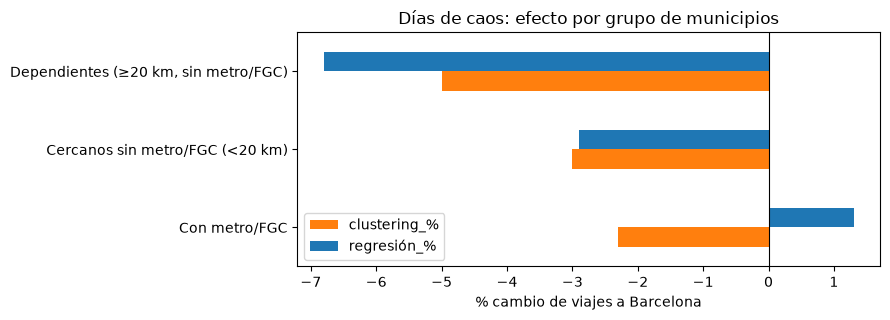

In [20]:
grupos = {"Dependientes (≥20 km, sin metro/FGC)": info.index[info.dependiente],
          "Cercanos sin metro/FGC (<20 km)": info.index[info.grupo == "Cercano sin metro/FGC"],
          "Con metro/FGC": info.index[info.con_alt]}
res_grupos = comparar(grupos, caos_real)
display(res_grupos); grafico_barras(res_grupos, "Días de caos: efecto por grupo de municipios")

**Resultado.** Los municipios dependientes de Rodalies son los que más reducen sus viajes a
Barcelona en los días de caos, con ambos métodos (−5,0 % con clustering, p = 0,001; −6,8 % con
regresión, p < 0,001).

En los municipios cercanos sin metro/FGC, ambos métodos estiman una caída pequeña (≈ −3 %), que es
significativa con el clustering (p = 0,006) pero no con la regresión (p = 0,10; IC 95 %: −6,2 % a
+0,6 %, que incluye el 0). Como la regresión descuenta el efecto común del día y es más exigente,
esta caída se considera no concluyente. En los municipios con metro/FGC no hay efecto según la
regresión (+1,3 %, n.s.).

**Conclusión:** con ambos métodos, el impacto se concentra en los municipios que dependen del tren.

### 7.2 ¿Depende de la distancia?

,municipios,clustering_%,clustering_p,regresión_%,regresión_IC95,regresión_p
grupo,,,,,,
Sin metro/FGC · < 15 km,8,-1.4,0.18,-1.7,"[-5.6, 2.5]",0.419
Sin metro/FGC · 15–30 km,16,-5.2,0.00,-3.4,"[-7.0, 0.4]",0.078
Sin metro/FGC · > 30 km,27,-6.2,0.00,-8.0,"[-11.5, -4.3]",0.000


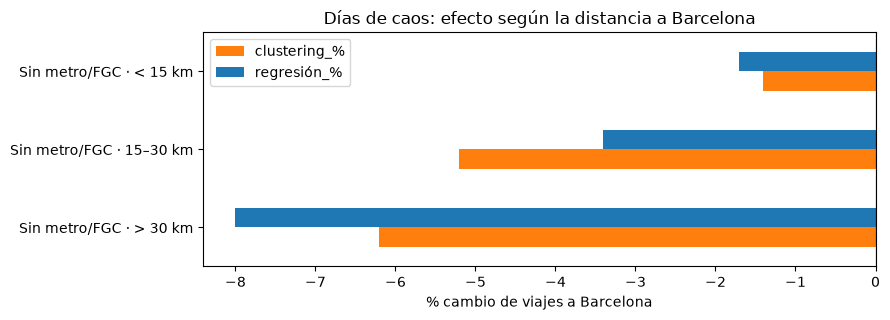

In [21]:
sin_alt = info[info.rodalies & ~info.con_alt]
bandas = pd.cut(sin_alt.dist_km, [0, 15, 30, 200], labels=["< 15 km", "15–30 km", "> 30 km"])
res_dist = comparar({f"Sin metro/FGC · {b}": sin_alt.index[bandas == b] for b in bandas.cat.categories}, caos_real)
display(res_dist); grafico_barras(res_dist, "Días de caos: efecto según la distancia a Barcelona")

**Resultado.** El efecto aumenta con la distancia a Barcelona, con ambos métodos:
≈ −1,5 % a menos de 15 km (no significativo), entre −3,4 % y −5,2 % entre 15 y 30 km
(significativo con el clustering; no concluyente con la regresión, p = 0,08) y entre −6,2 % y
−8,0 % a más de 30 km (significativo con ambos métodos, p < 0,01).

Cuanto más lejos y con menos alternativas, más viajes se pierden. Este gradiente, coherente en los
dos métodos, refuerza la interpretación de que el efecto se debe a la dependencia del tren.

### 7.3 ¿Qué corredor es más vulnerable?

grupo,R1,R2N,R2N+R3,R2S,R3,R4
2024-05-13 · Avería: robo de cobre en Montcada (día 1),-17.4,-2.7,-4.3,-5.3,1.6,-6.2
2025-03-17 · Huelga (caos generalizado),-6.9,-8.0,-6.5,-16.6,-19.7,-10.0
2025-03-26 · Huelga 24 h,1.2,2.1,9.7,-17.4,-6.1,-2.8
2025-04-01 · Huelga 24 h,-4.7,0.9,5.9,-17.4,-2.3,-6.6


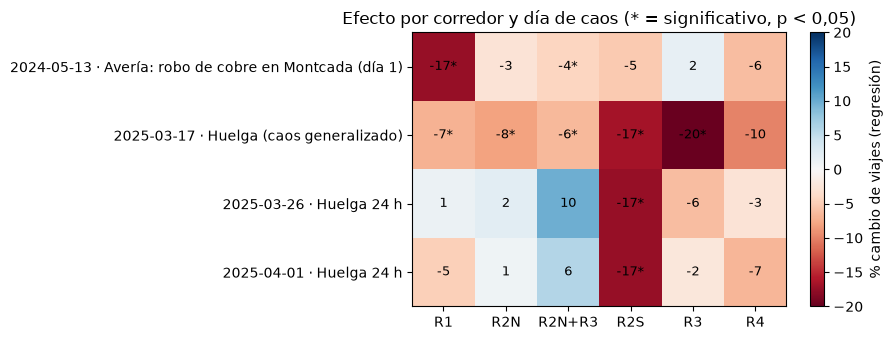

In [23]:
filas = {}
for d in caos_real:
    tab = comparar({l: dep.index[dep.lineas == l] for l in sorted(dep.lineas.unique())}, [d])
    filas[f"{d.date()} · {DIAS_CAOS[d.strftime('%Y-%m-%d')]}"] = tab["regresión_%"].where(tab["regresión_p"] < 0.05)
    filas[f"{d.date()} · {DIAS_CAOS[d.strftime('%Y-%m-%d')]}"].name = d
tabla_dias = pd.DataFrame({k: comparar({l: dep.index[dep.lineas == l] for l in sorted(dep.lineas.unique())}, [pd.Timestamp(k[:10])])["regresión_%"]
                           for k in filas}).T
signif = pd.DataFrame(filas).T.notna()
display(tabla_dias.round(1))

fig, ax = plt.subplots(figsize=(9, 3.5))
im = ax.imshow(tabla_dias.values, cmap="RdBu", vmin=-20, vmax=20, aspect="auto")
for i in range(tabla_dias.shape[0]):
    for j in range(tabla_dias.shape[1]):
        v = tabla_dias.iat[i, j]
        ax.text(j, i, f"{v:.0f}{'*' if signif.iat[i, j] else ''}", ha="center", va="center", fontsize=9)
ax.set_xticks(range(tabla_dias.shape[1]), tabla_dias.columns); ax.set_yticks(range(tabla_dias.shape[0]), tabla_dias.index)
plt.colorbar(im, label="% cambio de viajes (regresión)")
ax.set_title("Efecto por corredor y día de caos (* = significativo, p < 0,05)"); plt.tight_layout(); plt.show()

**Resultado: efecto por corredor y día.** El mapa muestra el efecto de cada día de caos en los
municipios dependientes de cada corredor (regresión; * = significativo).

- **R2 Sud (Garraf)** es el único corredor afectado en todas las huelgas (−17 % en las tres, siempre
  significativo). En cambio, el día de la avería del 13/05/2024, cuando la R2 Sud funcionaba con
  normalidad, no muestra efecto significativo (−5 %). El corredor cae cuando falla el tren y no cuando
  el tren funciona, lo que valida el método.
- **R1 (Maresme)** es el más afectado el día de la avería (−17 %), cuando solo circulaba entre Badalona
  y Arenys, y también cae en la huelga del 17/03 (−7 %).
- **R3 (Osona)** solo cae el 17/03 (−20 %), el día de caos más generalizado, en el que todos los
  corredores son negativos.
- **R2 Nord, Granollers y R4** no muestran efectos significativos, salvo el 17/03.

**Conclusión.** Hay dos tipos de días de caos: generalizados, en los que caen todos los corredores, y
parciales, en los que solo caen los corredores donde el servicio falla. El Garraf es el único corredor
estructuralmente vulnerable a las huelgas; el resto solo se ve afectado cuando el servicio se
interrumpe en su zona.

## 8. Estudio de dos días

Se analizan dos días de caos de naturaleza diferente: una huelga (17/03/2025) y una avería sin aviso
previo (13/05/2024). Para cada día se muestra:
1. **La cifra clave:** efecto en los municipios dependientes y en los que tienen alternativa (dos métodos).
2. **Un esquema de líneas:** cada fila es una línea de Rodalies y cada punto, un municipio situado según
   su distancia a Barcelona. Color = cambio de viajes (rojo = caída), tamaño = volumen y
   borde negro = efecto significativo.
3. **Los 10 municipios más afectados.**

In [34]:
from scipy.stats import norm

coords_mun = est.groupby("municipio_code")[["stop_lat", "stop_lon"]].mean()

def efectos_municipio(DIA):
    """Efecto por municipio (regresión) frente a lo esperado, con su z y su p."""
    D0 = todos[todos.fecha.isin(cal.index[cal.limpio])][["municipio_code", "fecha", "mun_dow", "y"]].copy()
    alpha = D0.groupby("mun_dow").y.mean()
    for _ in range(50):
        delta = (D0.y - D0.mun_dow.map(alpha)).groupby(D0.fecha).mean()
        alpha = (D0.y - D0.fecha.map(delta)).groupby(D0.mun_dow).mean()
    sd_res = (D0.y - D0.mun_dow.map(alpha) - D0.fecha.map(delta)).groupby(D0.municipio_code).std()
    Dd = todos[todos.fecha == DIA].set_index("municipio_code")
    base = Dd.mun_dow.map(alpha)
    ef_log = Dd.y - base - (Dd.y - base)[Dd.index.isin(ctrl_codes)].mean()
    r = info[info.rodalies].join(coords_mun).copy()
    r["efecto_%"] = ((np.exp(ef_log) - 1) * 100).reindex(r.index).round(1)
    r["z"] = (ef_log / sd_res).reindex(r.index).round(2)
    r["p"] = (2 * (1 - norm.cdf(r.z.abs()))).round(3)
    r["viajes_dia"] = Dd.viajes.reindex(r.index)
    return r.dropna(subset=["efecto_%"])


def esquema_lineas(r, ax):
    """Cada línea en una fila; cada municipio, en su distancia a Barcelona."""
    d = (r.assign(linea=r.lineas.str.split(",")).explode("linea")
           .assign(linea=lambda x: x.linea.str.strip()))
    d = d[d.linea.isin(LINEAS)].copy()
    lineas_ok = [l for l in LINEAS if l in set(d.linea)]
    orden = {l: i for i, l in enumerate(lineas_ok[::-1])}
    d["yy"] = d.linea.map(orden)

    for l, i in orden.items():
        fin = d.loc[d.linea == l, "dist_km"].max()
        ax.plot([0, fin + 2], [i, i], color="lightgrey", lw=6, zorder=0, solid_capstyle="round")

    sig = d.p < 0.05
    sc = ax.scatter(d.dist_km, d.yy, c=d["efecto_%"], cmap="RdBu", vmin=-25, vmax=25,
                    s=np.sqrt(d.viajes_dia) * 2.5, edgecolor=np.where(sig, "black", "grey"),
                    linewidth=np.where(sig, 1.8, 0.4), zorder=3)
    peores = d.drop_duplicates("municipio").nsmallest(8, "efecto_%").sort_values("dist_km")
    for k, (_, f) in enumerate(peores.iterrows()):
        ax.annotate(f"{f.municipio} {f['efecto_%']:.0f}%", (f.dist_km, f.yy),
                    xytext=(0, [9, -16, 22][k % 3]), textcoords="offset points",
                    ha="center", fontsize=8)

    ax.axvline(DIST_MIN_KM, color="black", ls="--", lw=0.8)
    ax.text(DIST_MIN_KM + 0.5, len(orden) - 0.45, f"{DIST_MIN_KM} km →\ndependientes", fontsize=8, va="top")
    ax.set_yticks(list(orden.values())); ax.set_yticklabels(list(orden.keys()))
    ax.set_ylim(-0.6, len(orden) - 0.4); ax.set_xlim(0, d.dist_km.max() + 4)
    ax.set_xlabel("Distancia a Barcelona (km)")
    ax.set_title("Efecto por municipio a lo largo de cada línea (borde negro = p < 0,05)")
    for s in ["top", "right", "left"]: ax.spines[s].set_visible(False)
    return sc


def estudio_dia(DIA, contexto=""):
    DIA = pd.Timestamp(DIA)
    print(f"{DIA.date()} · {DIAS_CAOS.get(DIA.strftime('%Y-%m-%d'), '')}")
    if contexto: print(contexto)

    # 1) Cifra clave por grupo
    t = comparar({"Dependientes": info.index[info.dependiente],
                  "Con alternativa (cercanos o con metro/FGC)": info.index[info.rodalies & ~info.dependiente]}, [DIA])
    display(t[["municipios", "clustering_%", "clustering_p", "regresión_%", "regresión_IC95", "regresión_p"]])

    r = efectos_municipio(DIA)
    fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1.6, 1]})

    # 2) Esquema de líneas
    sc = esquema_lineas(r, axes[0])
    plt.colorbar(sc, ax=axes[0], label="% cambio de viajes a Barcelona")

    # 3) Top 10 con su p
    ax = axes[1]
    top = r.nsmallest(10, "efecto_%").iloc[::-1]
    ax.barh(top.municipio + " (" + top.lineas + ")", top["efecto_%"],
            color=np.where(top.p < 0.05, "C3", "lightcoral"))
    for y, (_, f) in enumerate(top.iterrows()):
        ax.text(f["efecto_%"] - 0.5, y, f"p={f.p:.2f}", va="center", ha="right", fontsize=8)
    ax.axvline(0, color="black", lw=0.8); ax.set_xlabel("% cambio de viajes a Barcelona")
    ax.set_xlim(top["efecto_%"].min() - 8, 0)
    ax.set_title("Los 10 municipios más afectados (oscuro = p < 0,05)")
    plt.tight_layout(); plt.show()

    # 4) Tabla detallada del top 10
    display(r.nsmallest(10, "efecto_%")[["municipio", "lineas", "dist_km", "viajes_dia", "efecto_%", "z", "p"]]
              .round({"dist_km": 0}).reset_index(drop=True))
    return r

### 8.1 Huelga del 17/03/2025
Huelga de los sindicatos minoritarios contra el traspaso de Rodalies: retrasos y supresiones en toda la red.

2025-03-17 · Huelga (caos generalizado)


,municipios,clustering_%,clustering_p,regresión_%,regresión_IC95,regresión_p
grupo,,,,,,
Dependientes,35,-9.7,0.00,-10.8,"[-15.5, -5.8]",0.000
Con alternativa (cercanos o con metro/FGC),27,-2.7,0.14,0.2,"[-5.3, 6.1]",0.933


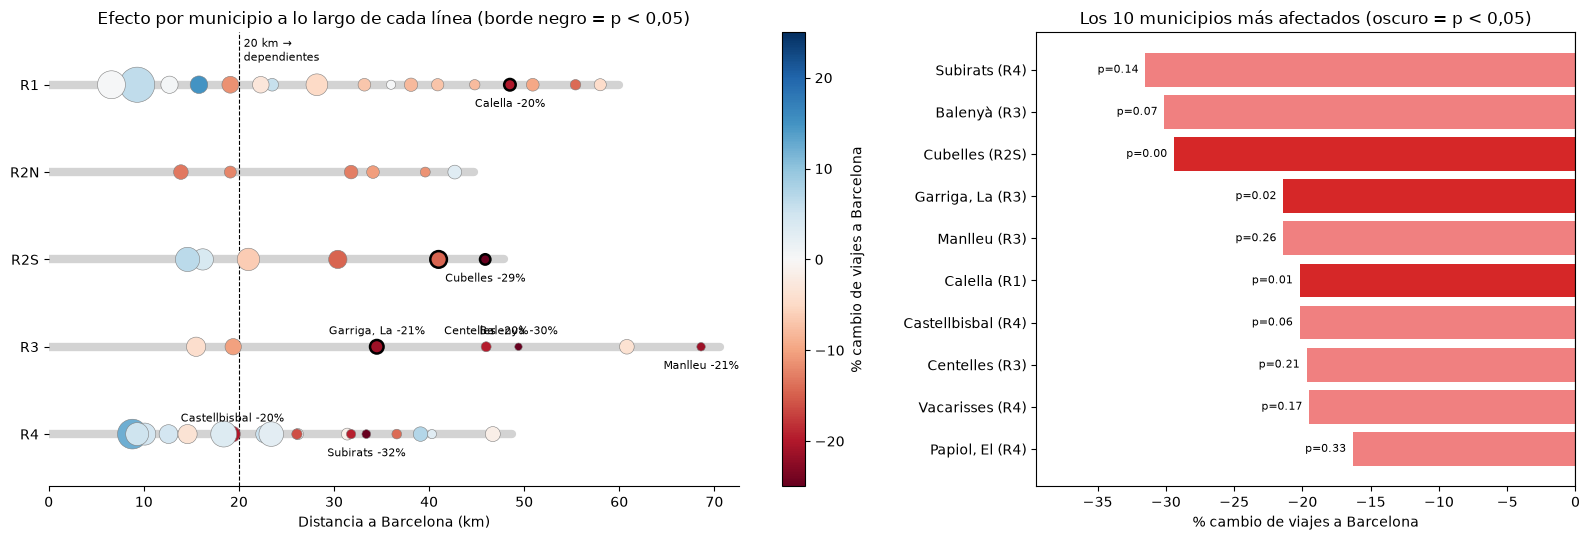

,municipio,lineas,dist_km,viajes_dia,efecto_%,z,p
0,Subirats,R4,33.0,256.0,-31.5,-1.47,0.142
1,Balenyà,R3,49.0,134.0,-30.1,-1.82,0.069
2,Cubelles,R2S,46.0,503.0,-29.4,-2.98,0.003
3,"Garriga, La",R3,34.0,1450.0,-21.4,-2.26,0.024
4,Manlleu,R3,69.0,225.0,-21.4,-1.12,0.263
5,Calella,R1,48.0,763.0,-20.2,-2.65,0.008
6,Castellbisbal,R4,19.0,2853.0,-20.2,-1.85,0.064
7,Centelles,R3,46.0,430.0,-19.7,-1.26,0.208
8,Vacarisses,R4,32.0,326.0,-19.5,-1.37,0.171
9,"Papiol, El",R4,15.0,860.0,-16.3,-0.97,0.332


In [32]:
r_17mar = estudio_dia("2025-03-17")

**Resultado.** Los municipios dependientes reducen sus viajes a Barcelona un **≈ 10 %** (−9,7 % con
clustering; −10,8 % con regresión, p < 0,001), mientras que los municipios con alternativa no muestran
cambios (+0,2 %, p = 0,93). El esquema de líneas muestra que la caída se concentra en los tramos alejados
de la R3 (Osona), la R2S (Garraf) y la R1 (Maresme norte). Individualmente, solo Cubelles (−29 %),
Calella (−20 %) y La Garriga (−21 %) son significativos (p < 0,05). Otros municipios pequeños, como
Subirats, Balenyà o Manlleu, caen entre un 20 % y un 30 %, pero su elevada variabilidad diaria impide
confirmarlo uno a uno. Por eso, la conclusión se basa en el efecto conjunto del grupo.

### 8.2 Incidencia 13/05/2024

2024-05-13 · Avería: robo de cobre en Montcada (día 1)


,municipios,clustering_%,clustering_p,regresión_%,regresión_IC95,regresión_p
grupo,,,,,,
Dependientes,35,-8.1,0.025,-8.6,"[-13.8, -3.1]",0.003
Con alternativa (cercanos o con metro/FGC),27,1.6,0.642,1.9,"[-2.7, 6.8]",0.424


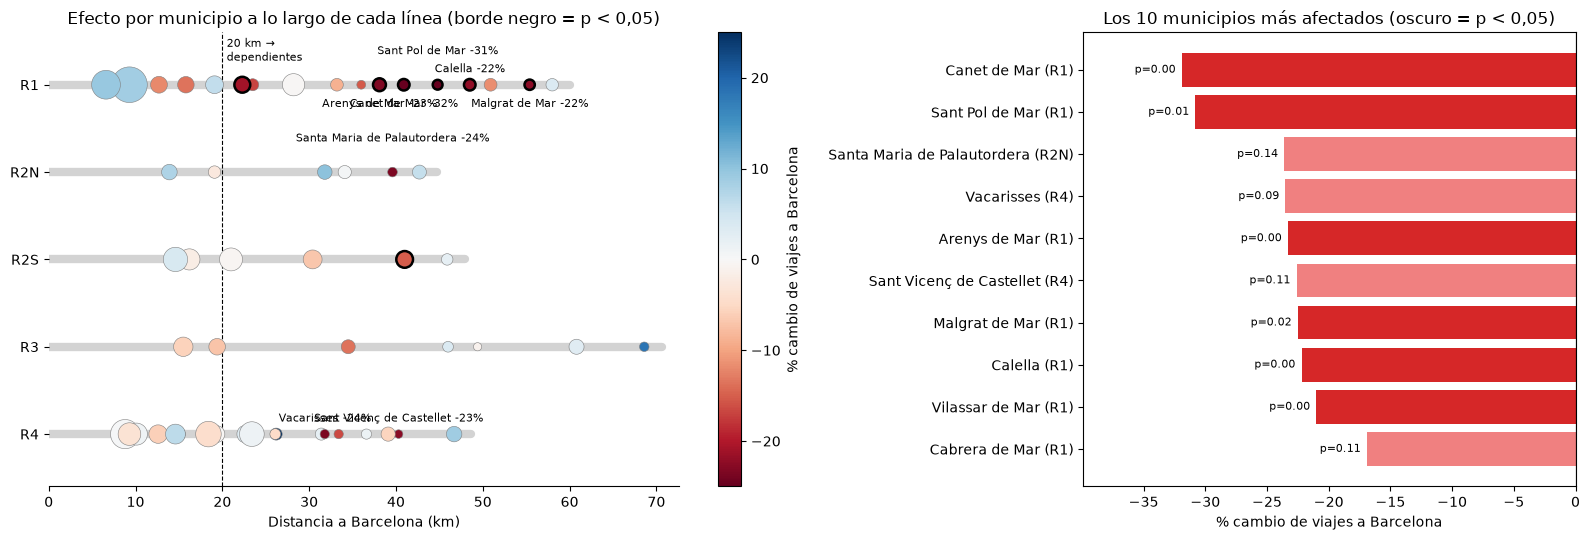

,municipio,lineas,dist_km,viajes_dia,efecto_%,z,p
0,Canet de Mar,R1,41.0,761.0,-31.9,-5.22,0.000
1,Sant Pol de Mar,R1,45.0,394.0,-30.8,-2.74,0.006
2,Santa Maria de Palautordera,R2N,40.0,373.0,-23.6,-1.49,0.136
3,Vacarisses,R4,32.0,320.0,-23.5,-1.69,0.091
4,Arenys de Mar,R1,38.0,1196.0,-23.3,-3.35,0.001
5,Sant Vicenç de Castellet,R4,40.0,234.0,-22.6,-1.60,0.110
6,Malgrat de Mar,R1,55.0,488.0,-22.5,-2.33,0.020
7,Calella,R1,48.0,768.0,-22.2,-2.95,0.003
8,Vilassar de Mar,R1,22.0,2739.0,-21.0,-4.38,0.000
9,Cabrera de Mar,R1,24.0,902.0,-16.9,-1.59,0.112


In [35]:
mun_13may = estudio_dia("2024-05-13")

**Resultado.** Los municipios dependientes reducen sus viajes un **≈ 8,5 %** (−8,1 % con clustering,
p = 0,025; −8,6 % con regresión, p = 0,003), mientras que los municipios con alternativa no cambian
(+1,9 %, p = 0,42). A diferencia de la huelga, la caída se concentra en un solo corredor, la **R1
(Maresme)**: 7 de los 10 municipios más afectados son de esta línea, y casi todos son significativos.
La caída es mayor al norte de Arenys de Mar, donde no había servicio (Canet −32 %, Sant Pol −31 %,
Malgrat −22 %, Calella −22 %). También es significativa entre Badalona y Arenys (Arenys −23 %,
Vilassar −21 %), donde el tren solo llegaba hasta Badalona y había que hacer transbordo. Que los datos
señalen exactamente el corredor afectado es una validación del método.

Sorprende que la R3 no muestre caída. Como los datos de Telefónica cuentan los viajes con cualquier
medio de transporte, una posible explicación es que sus usuarios fueron a Barcelona por carretera
(coche o autobús). Por tanto, el método mide los **viajes que dejan de hacerse**, no el cambio de modo.

## 9. Validaciones

### 9.1 Placebo
Se repite el análisis 200 veces con días **normales** elegidos al azar, como si fueran días de caos.
Si el método es correcto, con días normales el efecto debe ser ≈ 0, y el efecto real debe quedar
fuera de esa distribución.

Efecto real: -6.8 % · placebos: media -0.0 %, 95 % entre -2.8 % y 2.6 % · p = 0.005


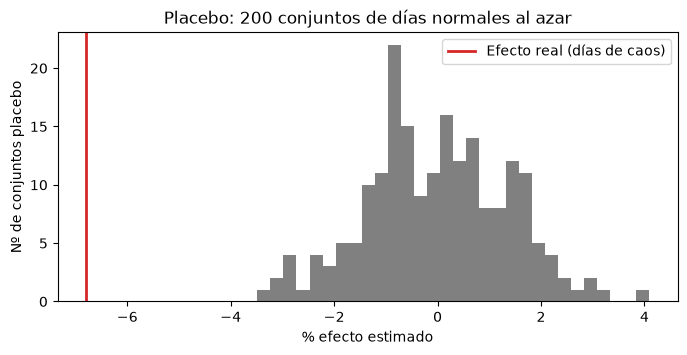

In [37]:
N_PLAC = 200
base = todos[todos.municipio_code.isin(info.index[info.dependiente | ~info.rodalies])].copy()
base["dependiente"] = base.municipio_code.isin(info.index[info.dependiente]).astype(int)
base["caos"] = base.fecha.isin(caos_real).astype(int)
obs = pf.feols("y ~ caos:dependiente | mun_dow + fecha", data=base, vcov={"CRV1": "municipio_code"}).coef().iloc[0]
pool = base.loc[base.caos == 0, "fecha"].drop_duplicates()
pool = pool[~pool.isin([d + pd.Timedelta(days=k) for d in caos_real for k in range(-3, 4)])]
rng = np.random.default_rng(0); plac = []
for _ in range(N_PLAC):
    falsos = rng.choice(pool.values, len(caos_real), replace=False)
    b = base[base.caos == 0].copy()
    b["falso"] = b.fecha.isin(falsos).astype(int) * b.dependiente
    plac.append(pf.feols("y ~ falso | mun_dow + fecha", data=b, vcov="iid").coef().iloc[0])
plac = np.array(plac)
p_plac = (np.sum(plac <= obs) + 1) / (N_PLAC + 1)
print(f"Efecto real: {(np.exp(obs) - 1) * 100:.1f} % · placebos: media {(np.exp(plac.mean()) - 1) * 100:.1f} %, "
      f"95 % entre {(np.exp(np.percentile(plac, 2.5)) - 1) * 100:.1f} % y {(np.exp(np.percentile(plac, 97.5)) - 1) * 100:.1f} % · p = {p_plac:.3f}")
ax = pd.Series((np.exp(plac) - 1) * 100).plot.hist(bins=30, color="grey", figsize=(8, 3.5))
ax.axvline((np.exp(obs) - 1) * 100, color="C3", lw=2, label="Efecto real (días de caos)")
plt.ylabel("Nº de conjuntos placebo")
ax.set_xlabel("% efecto estimado"); ax.set_title(f"Placebo: {N_PLAC} conjuntos de días normales al azar"); ax.legend(); plt.show()

**Resultado.** Con días normales elegidos al azar, el método da efectos de alrededor de 0 % (el 95 %,
entre −2,8 % y +2,6 %). El efecto en los días de caos reales (**−6,8 %**) queda muy lejos de esta
distribución: ninguno de los 200 placebos lo alcanza (**p = 0,005**, el mínimo posible con 200
repeticiones). Por lo tanto, la caída observada no es un artefacto del método, sino un efecto real de
los días de caos.

### 9.2 Event study: tendencias paralelas y duración del efecto

La regresión supone que, sin la incidencia, los municipios dependientes y los de control habrían
evolucionado igual (**tendencias paralelas**). Para comprobarlo, se estima el efecto en los municipios
dependientes no solo el día del caos, sino también en los **5 días laborables anteriores** y los
**3 posteriores**:

$$
\log(\text{viajes}_{m,t}) = \alpha_{m,\,\text{dow}} + \delta_t + \sum_{k=-5}^{3} \beta_k \cdot \mathbb{1}[\text{dependiente}_m]\cdot\mathbb{1}[t = \text{caos} + k] + \varepsilon_{m,t}
$$

- Si **antes del caos** (k < 0) los efectos son ≈ 0, los dos grupos evolucionaban igual y la comparación
  es válida.
- El efecto en **k = 0** es el impacto del día del caos.
- Los efectos **después del caos** (k > 0) indican si el impacto se mantiene los días siguientes.

Se usan días laborables (sin fines de semana ni festivos), de modo que k = 1 es el siguiente día de
trabajo.

,efecto_%,lo,hi,Pr(>|t|)
k,,,,
-5,0.25,-3.45,4.09,0.90
-4,-0.83,-4.21,2.66,0.63
-3,-2.83,-6.95,1.46,0.19
-2,-1.11,-4.74,2.65,0.55
-1,-1.38,-4.74,2.09,0.43
0,-6.84,-10.23,-3.32,0.00
1,-0.68,-4.33,3.12,0.72
2,1.93,-1.82,5.84,0.31
3,0.46,-3.54,4.63,0.82


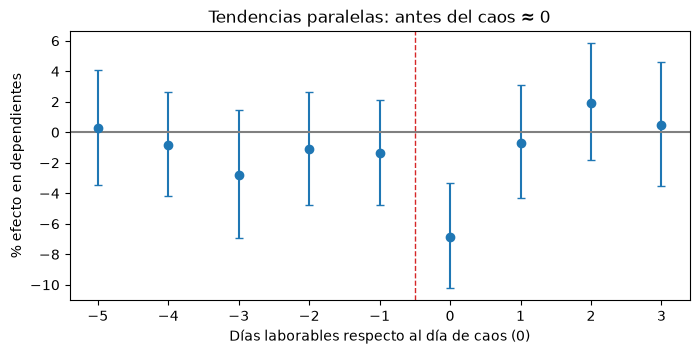

In [38]:
fechas_panel = np.sort(base.fecha.unique()); pos = {f: i for i, f in enumerate(fechas_panel)}
rel = pd.Series("fuera", index=pd.DatetimeIndex(fechas_panel))
for d in sorted(caos_real):
    i0 = pos[np.datetime64(d)]
    for k in range(-5, 4):
        j = i0 + k
        if 0 <= j < len(fechas_panel):
            f = fechas_panel[j]
            if rel[f] == "fuera" or abs(k) < abs(int(rel[f])): rel[f] = str(k)
es = base.copy()
es["rel_dep"] = np.where(es.dependiente == 1, es.fecha.map(rel), "fuera")
t = pf.feols("y ~ i(rel_dep, ref='fuera') | mun_dow + fecha", data=es, vcov={"CRV1": "municipio_code"}).tidy()
t["k"] = [int(i.split("::")[-1]) for i in t.index]; t = t.sort_values("k")
t["efecto_%"] = (np.exp(t.Estimate) - 1) * 100
t["lo"] = (np.exp(t["2.5%"]) - 1) * 100; t["hi"] = (np.exp(t["97.5%"]) - 1) * 100
display(t.set_index("k")[["efecto_%", "lo", "hi", "Pr(>|t|)"]].round(2))
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.errorbar(t.k, t["efecto_%"], yerr=[t["efecto_%"] - t.lo, t.hi - t["efecto_%"]], fmt="o", capsize=3)
ax.axhline(0, color="grey"); ax.axvline(-0.5, color="C3", ls="--", lw=1)
ax.set_xlabel("Días laborables respecto al día de caos (0)"); ax.set_ylabel("% efecto en dependientes")
ax.set_title("Tendencias paralelas: antes del caos ≈ 0"); plt.show()

**Resultado.** En los cinco días laborables anteriores al caos, el efecto en los municipios dependientes
no es significativo (todos los intervalos incluyen el 0; p ≥ 0,19): antes de la incidencia evolucionaban
igual que los municipios de control. Se cumple, por tanto, el supuesto de tendencias paralelas. El día del
caos, los viajes caen un **−6,8 %** (IC 95 % [−10,2, −3,3]) y, a partir del día siguiente, vuelven a
la normalidad (efectos entre −0,7 % y +1,9 %, no significativos). **El impacto se limita al mismo día de
la incidencia.** Los valores previos, ligeramente

## 9. Resumen: comparación de los 2 métodos

,municipios,clustering_%,clustering_p,regresión_%,regresión_IC95,regresión_p
grupo,,,,,,
Días de caos (media) · dependientes,35,-5.0,0.001,-6.8,"[-10.1, -3.4]",0.000
17/03/2025 huelga · dependientes,35,-9.7,0.000,-10.8,"[-15.5, -5.8]",0.000
13/05/2024 avería · dependientes,35,-8.1,0.025,-8.6,"[-13.8, -3.1]",0.003
13/05/2024 avería · dependientes R1,12,-11.9,0.000,-17.4,"[-23.7, -10.7]",0.000


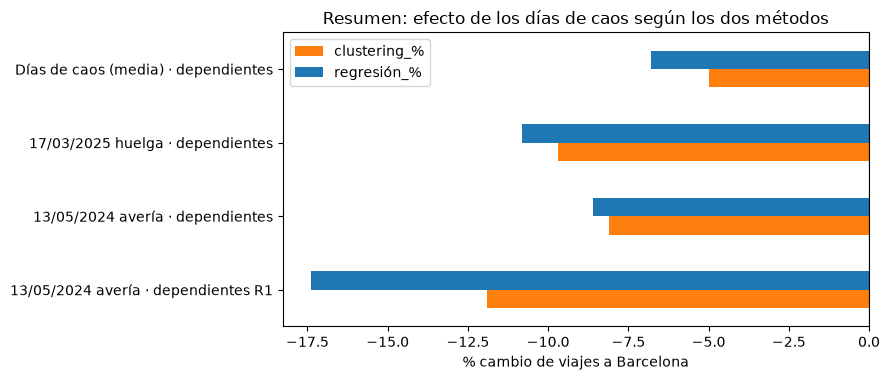

In [39]:
casos = {"Días de caos (media) · dependientes": (info.index[info.dependiente], caos_real),
         "17/03/2025 huelga · dependientes": (info.index[info.dependiente], [pd.Timestamp("2025-03-17")]),
         "13/05/2024 avería · dependientes": (info.index[info.dependiente], [pd.Timestamp("2024-05-13")]),
         "13/05/2024 avería · dependientes R1": (dep.index[dep.lineas == "R1"], [pd.Timestamp("2024-05-13")])}
filas = []
for nombre, (codes, dias) in casos.items():
    dias = [d for d in dias if d in caos_real]
    if dias: filas.append(comparar({nombre: codes}, dias))
resumen_final = pd.concat(filas)
display(resumen_final); resumen_final.to_csv(OUT / "resumen_final_metodos.csv")
grafico_barras(resumen_final, "Resumen: efecto de los días de caos según los dos métodos")

**Resultado.** Los dos métodos coinciden en todos los casos y todos los efectos son significativos:

| Caso | Clustering | Regresión |
|---|---|---|
| Días de caos (media) · dependientes | −5,0 % | −6,8 % |
| 17/03/2025, huelga · dependientes | −9,7 % | −10,8 % |
| 13/05/2024, avería · dependientes | −8,1 % | −8,6 % |
| 13/05/2024, avería · dependientes R1 | −11,9 % | −17,4 % |

La regresión da efectos algo mayores porque pondera igual cada municipio, mientras que el
clustering suma volúmenes y da más peso a los municipios grandes, que tienen más alternativas.

## 11. Conclusiones

1. **Las incidencias graves de Rodalies reducen los viajes a Barcelona solo donde el tren no tiene
   alternativa.** En los días de caos, los municipios dependientes (≥ 20 km y sin metro ni FGC)
   pierden entre un 7 % y un 11 % de sus viajes; los municipios cercanos o con metro/FGC no cambian.
2. **El efecto crece con la distancia** (≈ −2 % a < 15 km; ≈ −8 % a > 30 km).
3. **La vulnerabilidad varía por corredor y por día.** En promedio, el Garraf (R2S) es el más afectado;
   en cada incidencia concreta, el efecto se concentra donde se interrumpe el servicio (13/05/2024:
   municipios de la R1 al norte de Arenys).
4. **El impacto es puntual:** dura solo el día del caos y desaparece al día siguiente.
5. **Dos métodos independientes llegan a la misma conclusión**, validada con un placebo (p = 0,005)
   y una prueba de tendencias paralelas.

**Interpretación.** La gran mayoría de los usuarios mantiene el desplazamiento ante una incidencia,
cambiando de línea, de medio o de ruta. Solo donde no hay alternativa desaparece una parte de los
viajes (teletrabajo, aplazamiento).

**Limitaciones.**
- Los datos no identifican el medio de transporte y tienen resolución diaria.
- Hay pocos días de caos válidos (4); algunos corredores tienen pocos municipios.
- Los municipios de control pueden notar el caos de forma indirecta (tráfico): el efecto real podría
  ser algo mayor.
- En las incidencias largas que afectan solo a algunas líneas (Montcada 2024, Gavà 2023), el efecto es
  negativo pero débil y no concluyente, coherente con la adaptación de los usuarios.
- Los municipios muy pequeños quedan fuera (ceros por privacidad).

**Trabajo futuro.**
- **M3 (barrios de destino):** ver si en los días de caos cambian los barrios de llegada en Barcelona
  (menos llegadas a barrios con estación de Rodalies), como indicio de cambio de medio o de ruta.
- Datos horarios, validaciones de billetes (T-mobilitat) y aforos de tráfico.

## 12. Exportación para el análisis de M3

Se guardan los objetos necesarios para analizar M3 con exactamente los mismos criterios: el calendario
de días limpios (`cal`), los días de caos (`caos_real`), la clasificación de municipios (`info`), el
volumen de control (`vol_ctrl`) y el tipo de día asignado por el clustering (`tipos_dia`).

In [40]:
cal.to_parquet(OUT / "m2_cal.parquet")
info.to_parquet(OUT / "m2_info_municipios.parquet")
vol_ctrl.to_frame("vol_ctrl").to_parquet(OUT / "m2_vol_ctrl.parquet")
pd.Series(sorted(caos_real), name="fecha").to_frame().to_parquet(OUT / "m2_caos_real.parquet")

In [48]:
tipos_dia = pd.Series({d: tipo_de_dia(d) for d in vol_ctrl.index}, name="tipo")   # todos los días con datos
print(len(tipos_dia), "días con tipo asignado")
tipos_dia.astype(str).to_frame().to_parquet(OUT / "m2_tipos_dia.parquet")

300 días con tipo asignado


## 13. Exportación para el dashboard: página «Conclusiones»
Junta en un JSON los resultados de este notebook (efecto por municipio y por grupo en cada día de caos,
y event study) con los de M3 (barrios con y sin estación). El dashboard solo lee este fichero.
Se ejecuta **al final del notebook**, con todas las celdas anteriores ya ejecutadas.
Todo va dentro de una función para no sobrescribir variables del notebook (`info`, `OUT`, `t`…).

In [51]:
OUT = PROC / "rmove"
info = pd.read_parquet(OUT / "m2_info_municipios.parquet")
print(info.columns.tolist())   # debe aparecer 'municipio'

['municipio', 'rodalies', 'dependiente', 'con_alt', 'dist_km', 'lineas', 'grupo']


In [52]:
import hashlib, json, math

def exportar_conclusiones():
    destino = OUT / "conclusiones" / "dashboard_conclusiones.json"
    grupo_dashboard = {"Dependiente": "dependientes", "Cercano sin metro/FGC": "cercanos",
                       "Con metro/FGC": "metro_fgc", "Sin Rodalies (control)": "sin_rodalies"}
    titulos = {
        "2024-05-13": ("Avería de la R1 · Montcada", "Corte de todo el día. La caída se concentra en el Maresme norte."),
        "2025-03-17": ("Huelga de Rodalies", "Caos generalizado. Caen los corredores alejados: Osona (R3), Garraf (R2 Sud) y Maresme norte."),
        "2025-03-26": ("Huelga de 24 h", "Huelga anunciada: el total apenas cambia; en M3 los viajes se desplazan a barrios sin estación."),
        "2025-04-01": ("Huelga de 24 h", "Huelga anunciada: el total apenas cambia; en M3 los viajes se desplazan a barrios sin estación."),
    }

    def num(x, d=2):
        x = float(x)
        assert math.isfinite(x), "Valor no finito"
        return round(x, d)

    # Viajes de un día habitual: mediana en los días limpios (tamaño del círculo en el mapa).
    limpios = todos[todos.fecha.isin(cal.index[cal.limpio])]
    viajes_ref = limpios.groupby("municipio_code").viajes.median()

    grupos_reg = {"dependientes": info.index[info.dependiente],
                  "cercanos": info.index[info.grupo == "Cercano sin metro/FGC"],
                  "metro_fgc": info.index[info.con_alt]}

    mapa = []
    for d in sorted(caos_real):
        fecha = d.strftime("%Y-%m-%d")
        titulo, descripcion = titulos.get(fecha, (DIAS_CAOS.get(fecha, "Día de caos"), ""))
        r = efectos_municipio(d)                        # regresión por municipio (sección 8)
        tabla = comparar(grupos_reg, [d])                # efecto por grupo (dos métodos)
        print(f"{fecha}: {len(r)} municipios con Rodalies")
        mapa.append({
            "fecha": fecha, "titulo": titulo, "descripcion": descripcion,
            "grupos": [{"grupo": g, "efecto_pct": num(fila["regresión_%"]), "p_valor": num(fila["regresión_p"], 4)}
                       for g, fila in tabla.iterrows()],
            "municipios": [{"codigo": codigo, "nombre": f.municipio, "grupo": grupo_dashboard[f.grupo],
                            "lat": num(f.stop_lat, 5), "lon": num(f.stop_lon, 5),
                            "viajes_referencia": num(viajes_ref.get(codigo, f.viajes_dia), 0),
                            "efecto_pct": num(f["efecto_%"]), "p_valor": num(f.p, 4)}
                           for codigo, f in r.sort_index().iterrows()],
        })

    # Event study (sección 9.2), recalculado aquí para no depender de la variable global `t`.
    est_ev = pf.feols("y ~ i(rel_dep, ref='fuera') | mun_dow + fecha", data=es,
                      vcov={"CRV1": "municipio_code"}).tidy()
    est_ev["k"] = [int(i.split("::")[-1]) for i in est_ev.index]
    evento = [{"dia": int(f.k), "efecto_pct": num((np.exp(f.Estimate) - 1) * 100),
               "ic_inf": num((np.exp(f["2.5%"]) - 1) * 100), "ic_sup": num((np.exp(f["97.5%"]) - 1) * 100)}
              for _, f in est_ev.sort_values("k").iterrows()]
    assert [e["dia"] for e in evento] == list(range(-5, 4)), "El event study debe ir del día −5 al +3"
    dia0 = next(e for e in evento if e["dia"] == 0)

    # M3: barrios con y sin estación (regresión, municipios dependientes). Copiado de m3_hallazgos.md (H2).
    barrios = [
        {"caso": "Todos los días de caos", "sentido": "ida",    "con_estacion": -19.0, "sin_estacion": 1.8,   "p_diferencia": 0.0009},
        {"caso": "Todos los días de caos", "sentido": "vuelta", "con_estacion": -18.3, "sin_estacion": 4.9,   "p_diferencia": 0.0009},
        {"caso": "Huelga 17/03/2025",      "sentido": "ida",    "con_estacion": -18.4, "sin_estacion": -10.1, "p_diferencia": 0.235},
        {"caso": "Huelga 17/03/2025",      "sentido": "vuelta", "con_estacion": -14.1, "sin_estacion": 4.1,   "p_diferencia": 0.018},
        {"caso": "Avería 13/05/2024",      "sentido": "ida",    "con_estacion": -26.6, "sin_estacion": 2.8,   "p_diferencia": 0.003},
        {"caso": "Avería 13/05/2024",      "sentido": "vuelta", "con_estacion": -32.0, "sin_estacion": 3.1,   "p_diferencia": 0.001},
    ]  # «p < 0,001» se guarda como 0,0009 y el dashboard lo muestra como «< 0,001».

    def dep(fecha):
        caso = next(c for c in mapa if c["fecha"] == fecha)
        return next(g["efecto_pct"] for g in caso["grupos"] if g["grupo"] == "dependientes")
    fmt = lambda v: f"{v:+.1f}".replace(".", ",").replace("-", "−")

    conclusiones = [
        {"pregunta": "¿Qué pasa el primer día de un corte?",
         "titulo": "Se viaja menos desde los municipios que dependen del tren",
         "texto": (f"En los municipios dependientes de Rodalies los viajes a Barcelona caen: {fmt(dep('2025-03-17'))} % en la huelga "
                   f"del 17/03/2025 y {fmt(dep('2024-05-13'))} % en la avería del 13/05/2024. Donde hay metro o FGC no cambian. "
                   "El efecto crece con la distancia.")},
        {"pregunta": "¿Dónde se nota dentro de Barcelona?",
         "titulo": "En los barrios con estación",
         "texto": "La caída se concentra en los viajes hacia y desde los barrios con estación de Rodalies (−19 % a la ida y −18 % a la vuelta). "
                  "En los demás barrios no hay cambio. En las huelgas anunciadas el total casi no varía, pero los viajes se desplazan a barrios sin estación."},
        {"pregunta": "¿Cuánto dura el efecto?",
         "titulo": "Un día; después los viajes se recuperan",
         "texto": (f"El día de la incidencia el efecto es de {fmt(dia0['efecto_pct'])} %; del día +1 al +3 vuelve a ≈ 0. "
                   "En los cortes largos (Montcada a partir del día 5, Gavà) el efecto es débil: la gente se adapta y vuelve a viajar.")},
        {"pregunta": "¿Por qué el análisis general es más prudente?",
         "titulo": "Solo se detectan los cortes de todo el día",
         "texto": "Con datos diarios, los retrasos, los cortes de unas horas y las reducciones moderadas de servicio no cambian el volumen: "
                  "la gente llega tarde, pero viaja. El análisis general mezcla todas las incidencias del Excel, por eso su asociación es débil."},
    ]

    resultado = {
        "version_esquema": 1,
        "fuente": "R-MOVE · M2 (municipio → Barcelona, notebook 04) y M3 (municipio ↔ barrio), Telefónica Smart Steps",
        "periodo": {"inicio": INICIO, "fin": FIN},
        "kpis": [
            {"valor": len(caos_real), "decimales": 0, "unidad": "", "etiqueta": "Días de corte analizados"},
            {"valor": int(info.dependiente.sum()), "decimales": 0, "unidad": "", "etiqueta": "Municipios dependientes de Rodalies"},
            {"valor": dia0["efecto_pct"], "decimales": 1, "unidad": " %", "etiqueta": "Viajes el día del corte (dependientes)"},
            {"valor": -19.0, "decimales": 1, "unidad": " %", "etiqueta": "Hacia barrios con estación (M3)"},
        ],
        "mapa": mapa, "evento": evento, "barrios": barrios, "conclusiones": conclusiones,
        "metodo": {
            "mapa": "Efecto por municipio con la regresión de la sección 8: viajes del día frente a lo esperado para ese municipio y día de la semana, descontando el cambio medio de los municipios sin Rodalies. p a partir de la variabilidad del municipio en los días limpios. Solo municipios con Rodalies y ≥ 200 viajes/día; la posición es la media de sus estaciones.",
            "grupos": f"Dependientes: con Rodalies, sin metro ni FGC y a ≥ {DIST_MIN_KM} km de Plaça Catalunya. La media por grupo es la regresión DiD frente a los municipios sin Rodalies.",
            "evento": "Regresión DiD con efectos fijos (municipio × día de la semana y fecha), días laborables −5 a +3; errores agrupados por municipio.",
            "barrios": "M3, regresión con efecto fijo día × tipo de barrio; municipios dependientes con ≥ 200 viajes/día hacia cada tipo.",
        },
        "limitaciones": [
            "Datos diarios de todos los modos de transporte: no identifican el tren ni la hora.",
            "Solo cuatro días de corte válidos; en los municipios pequeños la significancia individual es baja.",
            "Los municipios de control pueden notar el caos de forma indirecta: el efecto real podría ser algo mayor.",
            "Las magnitudes de M3 no son comparables con las de M2; se comparan direcciones y diferencias dentro de M3.",
        ],
    }

    destino.parent.mkdir(parents=True, exist_ok=True)
    contenido = json.dumps(resultado, ensure_ascii=False, indent=1).encode("utf-8")
    destino.write_bytes(contenido)
    print(f"\nGuardado: {destino}")
    print("SHA-256 para publication.json:", hashlib.sha256(contenido).hexdigest())

exportar_conclusiones()

2024-05-13: 62 municipios con Rodalies
2025-03-17: 62 municipios con Rodalies
2025-03-26: 62 municipios con Rodalies
2025-04-01: 62 municipios con Rodalies

Guardado: c:\Users\marti\R-MOVE\data\processed\rmove\conclusiones\dashboard_conclusiones.json
SHA-256 para publication.json: bc5cf493fc6a9f6ceb5ca0202006c3f91081b83be5a9c87ea1138cd08ba04794
